<a href="https://colab.research.google.com/github/EzraSDev/DI_Bootcamp/blob/main/MiniProjectWeek3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
files.upload()

KeyboardInterrupt: 

In [ ]:
!unzip /content/AppleStockPricesFrom1981to2023.zip

Archive:  /content/AppleStockPricesFrom1981to2023.zip
  inflating: Apple Stock Prices (1981 to 2023).csv  


In [ ]:
import pandas as pd


In [ ]:
apple_df = pd.read_csv("/content/AppleStockPrices(1981to2023).csv")

In [ ]:
apple_df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,02/01/1981,0.154018,0.155134,0.154018,0.154018,0.119849,21660800
1,05/01/1981,0.151228,0.151228,0.150670,0.150670,0.117244,35728000
2,06/01/1981,0.144531,0.144531,0.143973,0.143973,0.112032,45158400
3,07/01/1981,0.138393,0.138393,0.137835,0.137835,0.107256,55686400
4,08/01/1981,0.135603,0.135603,0.135045,0.135045,0.105085,39827200


In [ ]:
apple_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10608 entries, 0 to 10607
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       10608 non-null  object 
 1   Open       10608 non-null  float64
 2   High       10608 non-null  float64
 3   Low        10608 non-null  float64
 4   Close      10608 non-null  float64
 5   Adj Close  10608 non-null  float64
 6   Volume     10608 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 580.3+ KB


In [ ]:
apple_df.isnull().sum()

,0
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0


In [ ]:
apple_df.duplicated().sum()

np.int64(0)

In [ ]:
apple_df.dtypes

,0
Date,object
Open,float64
High,float64
Low,float64
Close,float64
Adj Close,float64
Volume,int64


In [ ]:
apple_df['Date'].min()
apple_df['Date'].max()

'31/12/2021'

In [ ]:
apple_df['Date'] = pd.to_datetime(apple_df['Date'], dayfirst=True)

In [ ]:
from numpy import diff
apple_df['Date_Diff'] = apple_df['Date'].diff()

In [ ]:
apple_df['Date'].diff().value_counts()

,count
Date,
1 days,8317
3 days,1927
4 days,265
2 days,95
5 days,2
7 days,1


The stock market had 8317 consecutive days trding, 1927 weekends, 95 probably hollidays, 265 probaly long weekends, 2 five days extended closure, and 1 7 days extended closure.

In [ ]:
apple_df[apple_df['Date'].diff() > pd.Timedelta(days=4)][['Date']]

,Date
5229,2001-09-17
6562,2007-01-03
8030,2012-10-31


In [ ]:
apple_df['Date'].is_monotonic_increasing

True

In [ ]:
import matplotlib.pyplot as plt

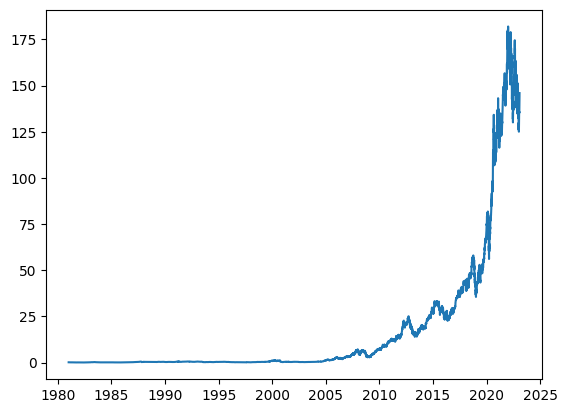

In [ ]:
plt.plot(apple_df['Date'], apple_df['Close'])

Apple's stock prices show a significant long term upward trend.
From 1981 until around 2017, the stock prices appears low compared to its later values. After the introduction of the IPhone in 2007, the stock experienced fluctuations and gradual growth.
From around 2010 onwards apple expierenced substantial growth,with several periods of the cline within them.
From 2015 onward apple expirenced substantial growth, reaching all time highs followed by temporary correction.
betwen 2021 and 2023 apple expirenced further growth reaching new highs, altouth this was accompanined by a series of declining prices.

Part 2

In [ ]:
!pip install mplfinance

In [ ]:
import mplfinance as mpf

In [ ]:
apple_df = apple_df.set_index('Date')

In [ ]:
apple_df[['Open', 'High', 'Low', 'Close']].head()

,Open,High,Low,Close
Date,,,,
1981-01-02,0.154018,0.155134,0.154018,0.154018
1981-01-05,0.151228,0.151228,0.150670,0.150670
1981-01-06,0.144531,0.144531,0.143973,0.143973
1981-01-07,0.138393,0.138393,0.137835,0.137835
1981-01-08,0.135603,0.135603,0.135045,0.135045


In [ ]:
del min

In [ ]:
recent_df = apple_df.tail(100)

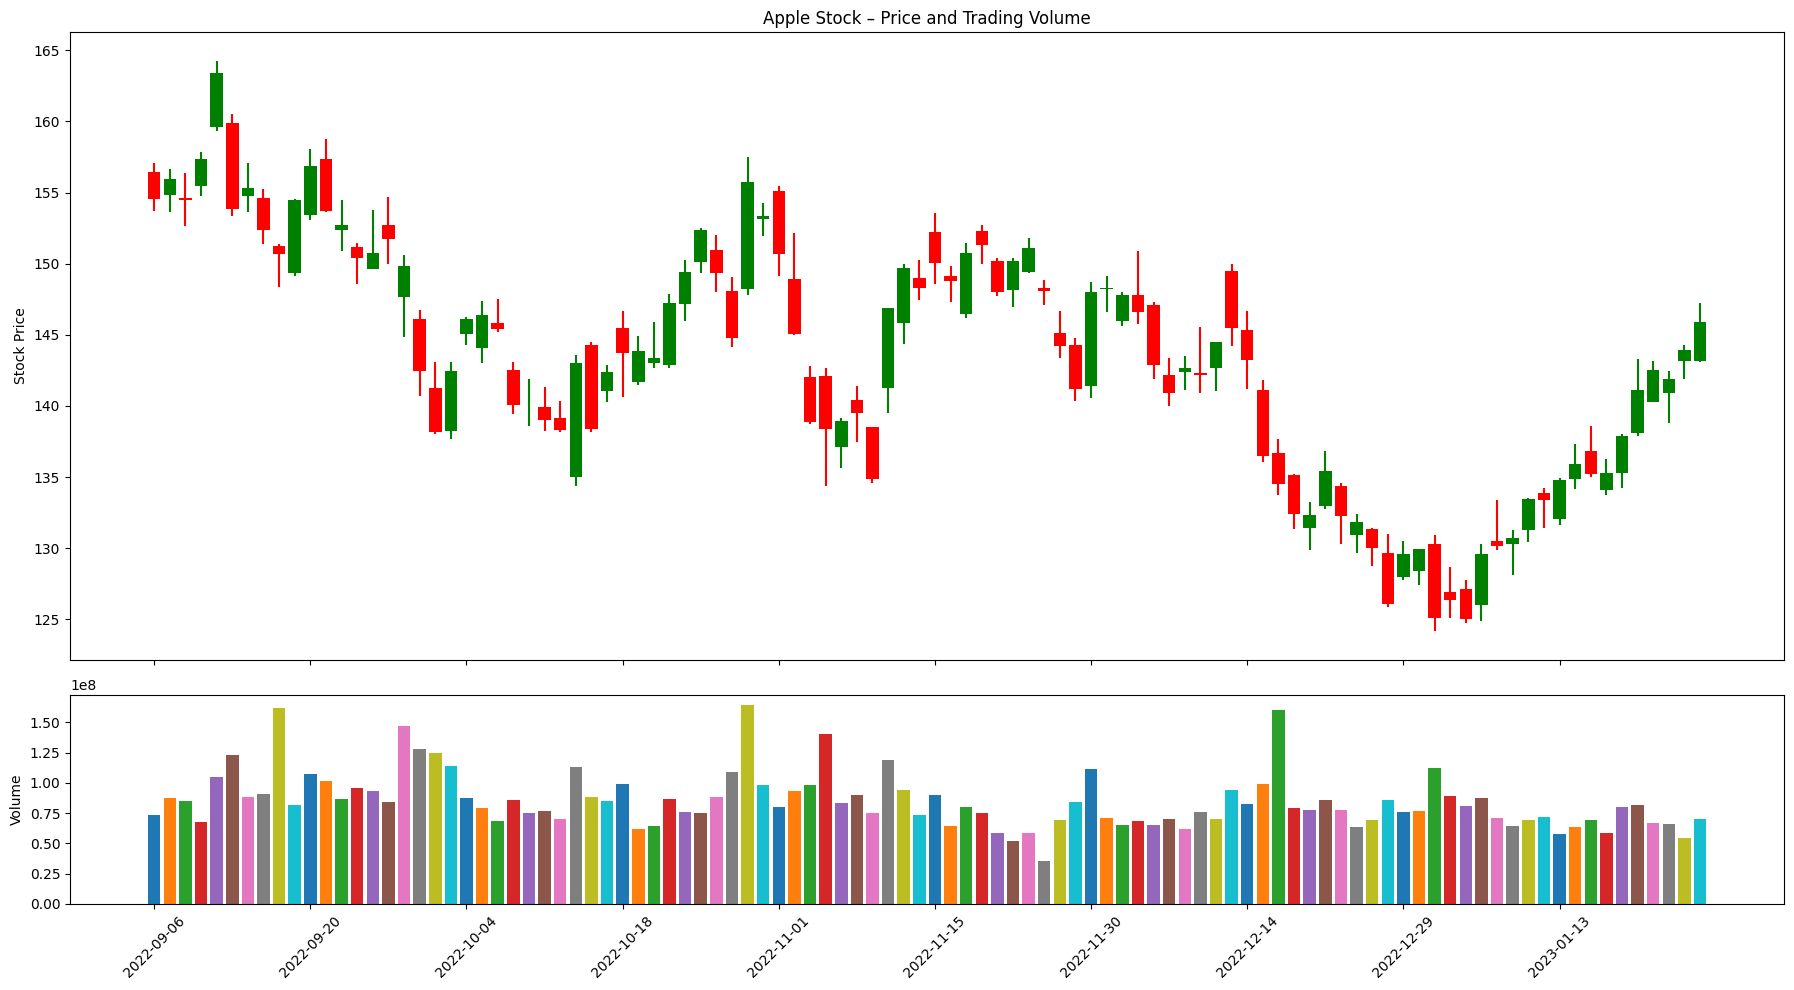

In [ ]:
# 1. Create the figure
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(18, 10),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)

# 2. Draw candles and volume
for i, (date, row) in enumerate(recent_df.iterrows()):

    open_price = row['Open']
    high_price = row['High']
    low_price = row['Low']
    close_price = row['Close']

    color = 'green' if close_price >= open_price else 'red'

    # Candlestick wick
    ax1.vlines(i, low_price, high_price, color=color)

    # Candlestick body
    height = abs(close_price - open_price)
    bottom = min(open_price, close_price)
    ax1.bar(i, height, bottom=bottom, width=0.8, color=color)

    # Volume
    ax2.bar(i, row['Volume'])

# 3. Format charts
ax1.set_title('Apple Stock – Price and Trading Volume')
ax1.set_ylabel('Stock Price')
ax2.set_ylabel('Volume')

# 4. Format dates
tick_positions = range(0, len(recent_df), 10)

ax2.set_xticks(tick_positions)
ax2.set_xticklabels(
    recent_df.index[list(tick_positions)].strftime('%Y-%m-%d'),
    rotation=45
)

# 5. Display
plt.tight_layout()
plt.show()

(array([19236., 19266., 19297., 19327., 19358., 19389.]),
 [Text(19236.0, 0, '2022-09'),
  Text(19266.0, 0, '2022-10'),
  Text(19297.0, 0, '2022-11'),
  Text(19327.0, 0, '2022-12'),
  Text(19358.0, 0, '2023-01'),
  Text(19389.0, 0, '2023-02')])

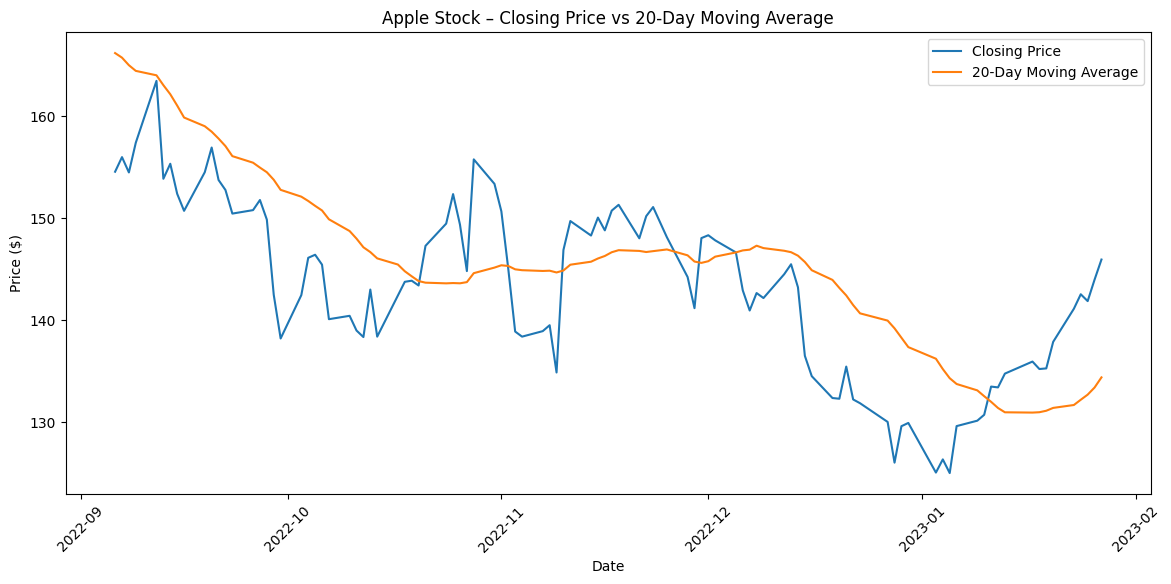

In [ ]:
apple_df['MA20'] = apple_df['Close'].rolling(window=20).mean()
recent_df = apple_df.tail(100)
plt.figure(figsize=(14, 6))
plt.plot(recent_df.index, recent_df['Close'], label='Closing Price')
plt.plot(recent_df.index, recent_df['MA20'], label='20-Day Moving Average')
plt.title('Apple Stock – Closing Price vs 20-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.xticks(rotation=45)

In [ ]:
apple_df['Close'].mean()


np.float64(16.69736201451735)

In [ ]:
apple_df['Close'].median()

0.487701

In [ ]:
apple_df['Close'].std()


35.47391163938849

In [ ]:
apple_df.index.year.unique()

Index([1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992,
       1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016,
       2017, 2018, 2019, 2020, 2021, 2022, 2023],
      dtype='int32', name='Date')

In [ ]:
prices_2021 = apple_df.loc[apple_df.index.year == 2021, 'Close']

prices_2022 = apple_df.loc[apple_df.index.year == 2022, 'Close']

In [ ]:
from scipy.stats import ttest_ind

In [ ]:
t_stat, p_value = ttest_ind(prices_2021, prices_2022)

In [ ]:
print("T-statistic:", t_stat)
print(f"P-value: {p_value:.6f}")

T-statistic: -11.183996762023252
P-value: 0.000000


The independent two-sample t-test found a statistically significant difference between Apple's average daily closing prices in 2021 and 2022 (t = -11.184, p < 0.05). The average closing price was higher in 2022.

In [ ]:
apple_df['Daily Return'] = apple_df['Close'].pct_change()

In [ ]:
apple_df[['Close', 'Daily Return']].head()

,Close,Daily Return
Date,,
1981-01-02,0.154018,NaN
1981-01-05,0.150670,-0.021738
1981-01-06,0.143973,-0.044448
1981-01-07,0.137835,-0.042633
1981-01-08,0.135045,-0.020242


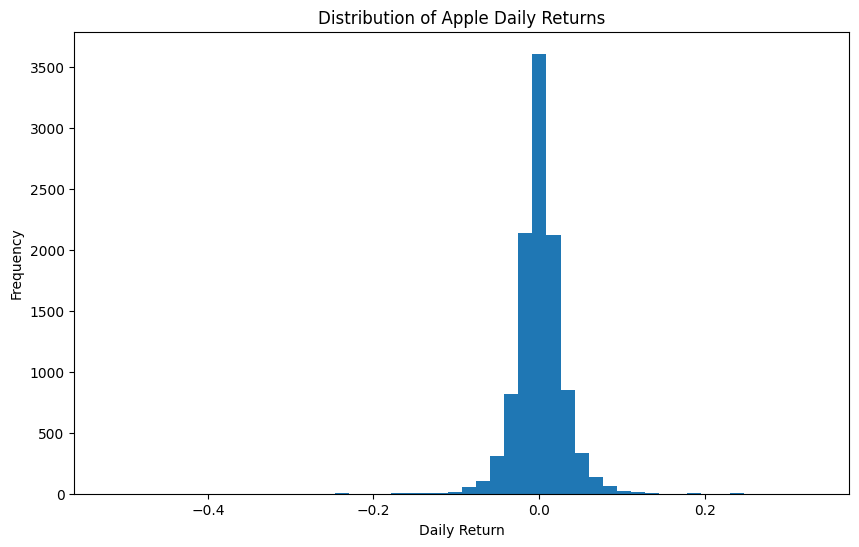

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(apple_df['Daily Return'].dropna(), bins=50)

plt.title('Distribution of Apple Daily Returns')
plt.xlabel('Daily Return')
plt.ylabel('Frequency')

plt.show()

In [ ]:
from scipy.stats import shapiro

In [ ]:
stat, p_value = shapiro(apple_df['Daily Return'].dropna())

print(f"Shapiro-Wilk statistic: {stat:.6f}")
print(f"P-value: {p_value:.6e}")

Shapiro-Wilk statistic: 0.919058
P-value: 1.789829e-59


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10607.
  res = hypotest_fun_out(*samples, **kwds)
